# Прогнозування відтоку клієнтів для телекомунікаційної компанії

## 1. Вступ

Метою цього проєкту є розробка моделі машинного навчання для прогнозування відтоку клієнтів телекомунікаційної компанії.

На основі історичних даних про клієнтів модель повинна визначати ймовірність того, що клієнт припинить користуватися послугами компанії.

У межах проєкту буде проведено аналіз даних, попередню обробку, побудовано та порівняно моделі машинного навчання, виконано оцінювання їхньої якості та реалізовано прогнозування ймовірності відтоку для нового клієнта.

Основна увага приділяється метрикам Accuracy, Precision, Recall та F1-score. Особливо важливою є метрика Recall, оскільки для бізнесу важливо правильно виявляти клієнтів, які можуть припинити користуватися послугами.

## Цілі проєкту

- дослідити дані про клієнтів телекомунікаційної компанії;
- виявити пропущені та потенційно проблемні значення;
- проаналізувати залежності між характеристиками клієнтів та відтоком;
- підготувати дані для машинного навчання;
- побудувати та порівняти моделі класифікації;
- виконати підбір параметрів моделей за допомогою крос-валідації;
- оцінити моделі за Accuracy, Precision, Recall та F1-score;
- визначити найкращу модель;
- отримувати ймовірність відтоку для нового клієнта;
- створити зрозумілий результат прогнозування.



## 2. Імпорт бібліотек

Для виконання проєкту використовуватимемо бібліотеки Python для аналізу даних, їх візуалізації, попередньої обробки та побудови моделей машинного навчання.

Pandas і NumPy допоможуть працювати з даними, Matplotlib і Seaborn — візуалізувати результати, а Scikit-learn — підготувати дані, навчити моделі та оцінити їхню якість.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

## 3. Завантаження та первинний огляд даних

На цьому етапі буде завантажено набір даних клієнтів телекомунікаційної компанії та проведено його первинний огляд.

Мета цього етапу — визначити структуру набору даних, кількість записів і ознак, типи даних, а також перевірити наявність пропущених значень.

Отримані результати допоможуть визначити подальші кроки аналізу та підготовки даних до машинного навчання.

Для подальшого аналізу використовується файл internet_service_churn.csv, який містить дані про клієнтів телекомунікаційної компанії.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving internet_service_churn.csv to internet_service_churn.csv


## 4. Первинний огляд даних

### 4.1. Завантаження даних

За допомогою бібліотеки Pandas завантажимо CSV-файл у DataFrame — табличну структуру даних Python.

Це дозволить переглянути записи про клієнтів, дослідити характеристики даних і підготувати їх до подальшого аналізу.

In [ ]:
import pandas as pd

df = pd.read_csv("/content/internet_service_churn.csv")

print("Дані успішно завантажено!")

Дані успішно завантажено!


### 4.2. Перегляд перших записів

Переглянемо перші п'ять рядків набору даних, щоб ознайомитися зі структурою таблиці, назвами стовпців і прикладами значень.

In [ ]:
df.head()

,id,is_tv_subscriber,is_movie_package_subscriber,subscription_age,bill_avg,reamining_contract,service_failure_count,download_avg,upload_avg,download_over_limit,churn
0,15,1,0,11.95,25,0.14,0,8.4,2.3,0,0
1,18,0,0,8.22,0,NaN,0,0.0,0.0,0,1
2,23,1,0,8.91,16,0.00,0,13.7,0.9,0,1
3,27,0,0,6.87,21,NaN,1,0.0,0.0,0,1
4,34,0,0,6.39,0,NaN,0,0.0,0.0,0,1


### 4.3. Розмір набору даних

Визначимо кількість записів і ознак у наборі даних. Це допоможе оцінити обсяг інформації, доступної для аналізу та навчання моделі.

In [ ]:
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Кількість рядків: 72274
Кількість стовпців: 11


**Результат первинного огляду**

Набір даних містить 72 274 рядки та 11 стовпців. Кожен рядок відповідає запису про клієнта, а стовпці містять характеристики, які можуть бути корисними для прогнозування відтоку клієнтів.

Для подальшого аналізу необхідно дослідити типи даних, перевірити наявність пропущених значень і визначити цільову змінну `churn`.

### 4.4. Перевірка структури даних

За допомогою методу `info()` перевіримо структуру набору даних. Він дозволяє переглянути назви стовпців, кількість заповнених значень, типи даних і загальну інформацію про таблицю.

Ця перевірка допоможе визначити, чи потрібні додаткові кроки для підготовки даних перед побудовою моделей машинного навчання.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72274 entries, 0 to 72273
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           72274 non-null  int64  
 1   is_tv_subscriber             72274 non-null  int64  
 2   is_movie_package_subscriber  72274 non-null  int64  
 3   subscription_age             72274 non-null  float64
 4   bill_avg                     72274 non-null  int64  
 5   reamining_contract           50702 non-null  float64
 6   service_failure_count        72274 non-null  int64  
 7   download_avg                 71893 non-null  float64
 8   upload_avg                   71893 non-null  float64
 9   download_over_limit          72274 non-null  int64  
 10  churn                        72274 non-null  int64  
dtypes: float64(4), int64(7)
memory usage: 6.1 MB


Аналіз структури даних
Набір даних містить 72 274 записи та 11 ознак.

Усі змінні представлені числовими типами даних:

7 ознак мають тип int64;
4 ознаки мають тип float64.
Цільовою змінною є churn, яка використовується для прогнозування відтоку клієнтів.

Під час аналізу структури даних були виявлені пропущені значення у трьох ознаках:

reamining_contract;
download_avg;
upload_avg.
Найбільша кількість пропусків спостерігається в ознаці reamining_contract, тому на етапі попередньої обробки буде проведено додатковий аналіз та обрано відповідний метод заповнення пропущених значень.

### 4.5. Статистичний аналіз числових ознак

За допомогою методу `describe()` проведемо первинний статистичний аналіз числових ознак набору даних.

Розглянемо середні значення, стандартні відхилення, мінімальні та максимальні значення, а також квартилі. Це допоможе краще зрозуміти характеристики клієнтів і виявити можливі аномалії в даних.

In [ ]:
df.describe()

,id,is_tv_subscriber,is_movie_package_subscriber,subscription_age,bill_avg,reamining_contract,service_failure_count,download_avg,upload_avg,download_over_limit,churn
count,7.227400e+04,72274.000000,72274.000000,72274.000000,72274.000000,50702.000000,72274.000000,71893.000000,71893.000000,72274.000000,72274.000000
mean,8.463182e+05,0.815259,0.334629,2.450051,18.942483,0.716039,0.274234,43.689911,4.192076,0.207613,0.554141
std,4.891022e+05,0.388090,0.471864,2.034990,13.215386,0.697102,0.816621,63.405963,9.818896,0.997123,0.497064
min,1.500000e+01,0.000000,0.000000,-0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.222165e+05,1.000000,0.000000,0.930000,13.000000,0.000000,0.000000,6.700000,0.500000,0.000000,0.000000
50%,8.477840e+05,1.000000,0.000000,1.980000,19.000000,0.570000,0.000000,27.800000,2.100000,0.000000,1.000000
75%,1.269562e+06,1.000000,1.000000,3.300000,22.000000,1.310000,0.000000,60.500000,4.800000,0.000000,1.000000
max,1.689744e+06,1.000000,1.000000,12.800000,406.000000,2.920000,19.000000,4415.200000,453.300000,7.000000,1.000000


### Висновки за результатами статистичного аналізу

Статистичний аналіз показав, що набір даних містить числові ознаки з різними діапазонами значень. Для деяких характеристик, зокрема `bill_avg` і `download_avg`, спостерігаються значні максимальні значення, які потребують додаткового дослідження.

Також підтверджено наявність пропущених значень у стовпцях `reamining_contract`, `download_avg` та `upload_avg`.

Середнє значення цільової змінної `churn` становить приблизно 0,554. Якщо змінна закодована значеннями 0 і 1, це відповідає приблизно 55,4% записів із `churn = 1`.

Надалі необхідно перевірити пропущені значення та дослідити розподіл цільової змінної.

### 4.6. Перевірка пропущених значень

На цьому етапі перевіримо наявність пропущених значень у кожному стовпці набору даних і визначимо їхню кількість.

Результати перевірки допоможуть оцінити повноту даних і спланувати їхню попередню обробку перед навчанням моделей машинного навчання.

In [ ]:
missing_values = df.isnull().sum()

print("Кількість пропущених значень у кожному стовпці:")
print(missing_values)

Кількість пропущених значень у кожному стовпці:
id                                 0
is_tv_subscriber                   0
is_movie_package_subscriber        0
subscription_age                   0
bill_avg                           0
reamining_contract             21572
service_failure_count              0
download_avg                     381
upload_avg                       381
download_over_limit                0
churn                              0
dtype: int64


### Висновки щодо пропущених значень

Перевірка показала, що пропущені значення містяться у трьох стовпцях: `reamining_contract`, `download_avg` та `upload_avg`.

У стовпці `reamining_contract` виявлено 21 572 пропущені значення, що становить приблизно 29,85% набору даних. У стовпцях `download_avg` та `upload_avg` відсутні по 381 значенню, або приблизно 0,53%.

В інших стовпцях пропущених значень немає.

Оскільки кількість пропусків у `reamining_contract` є значною, перед навчанням моделей необхідно додатково дослідити цю ознаку та визначити відповідний спосіб обробки пропущених значень. Видаляти записи на цьому етапі недоцільно без додаткового аналізу.

### 4.6.1. Аналіз пропущених значень

Після визначення кількості пропущених значень проведемо детальніший аналіз їхнього розподілу в наборі даних.

Для кожного стовпця обчислимо кількість пропусків і їхній відсоток від загальної кількості записів. Результати представимо у вигляді таблиці, відсортованої за спаданням частки пропущених значень.

Це допоможе оцінити масштаб проблеми та визначити, які ознаки потребують особливої уваги під час попередньої обробки даних.

In [ ]:

missing = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Відсоток пропусків": df.isnull().mean() * 100
})

missing = missing[missing["Кількість пропусків"] > 0]

missing.sort_values("Відсоток пропусків", ascending=False)


,Кількість пропусків,Відсоток пропусків
reamining_contract,21572,29.847525
download_avg,381,0.527161
upload_avg,381,0.527161


#### Результат аналізу пропущених значень

Аналіз показав, що найбільша частка пропущених значень припадає на ознаку `reamining_contract` — приблизно 29,85%. У стовпцях `download_avg` та `upload_avg` частка пропусків становить близько 0,53% у кожному.

Оскільки в `reamining_contract` відсутні значення майже в третині записів, цю ознаку необхідно дослідити окремо перед вибором способу обробки пропусків. Для двох інших ознак кількість пропусків значно менша.

На цьому етапі пропущені значення не видаляємо й не заповнюємо, оскільки спосіб обробки потрібно обґрунтувати під час підготовки даних до моделювання.

### 4.7. Перевірка дублікатів

На цьому етапі перевіримо набір даних на наявність повністю однакових рядків.

Дублікати можуть призводити до повторного врахування тих самих записів під час аналізу та навчання моделей машинного навчання. Тому перед подальшою обробкою даних необхідно визначити кількість таких записів і вирішити, чи потрібне їх видалення.

In [ ]:
duplicates_count = df.duplicated().sum()

print("Кількість повних дублікатів:", duplicates_count)

Кількість повних дублікатів: 0


#### Висновки щодо дублікатів

За результатами перевірки в наборі даних не виявлено повністю однакових рядків. Кількість дублікатів становить 0.

Отже, видалення повних дублікатів на цьому етапі не потрібне. Набір даних можна використовувати для подальшого дослідницького аналізу.

### 4.8. Перевірка унікальності ідентифікатора

Стовпець `id` містить ідентифікатори записів про клієнтів. Перевіримо, чи кожному запису відповідає унікальний ідентифікатор.

Це необхідно, щоб виявити можливі повторення ідентифікаторів і перевірити коректність структури набору даних. Ідентифікатор також буде розглянуто окремо під час підготовки ознак для моделі, оскільки він сам по собі не описує поведінку клієнта.

In [ ]:
print("Кількість записів:", len(df))
print("Кількість унікальних ID:", df["id"].nunique())
print("Кількість повторних ID:", df["id"].duplicated().sum())

Кількість записів: 72274
Кількість унікальних ID: 72274
Кількість повторних ID: 0


#### Висновки щодо унікальності ідентифікатора

У наборі даних міститься 72 274 записи та 72 274 унікальні ідентифікатори. Повторних значень у стовпці `id` не виявлено.

Отже, кожен запис має унікальний ідентифікатор. Оскільки `id` виконує технічну функцію і не характеризує поведінку клієнта, під час побудови моделей машинного навчання його буде виключено з набору ознак.

### 4.9. Аналіз цільової змінної `churn`

Цільова змінна `churn` відображає наявність або відсутність відтоку клієнта. У межах цього етапу дослідимо розподіл її значень, визначимо кількість записів кожного класу та їхню частку у відсотках.

Результати допоможуть оцінити баланс класів і врахувати його під час побудови моделей класифікації.

In [ ]:
churn_counts = df["churn"].value_counts().sort_index()
churn_percent = df["churn"].value_counts(normalize=True).sort_index() * 100

churn_distribution = pd.DataFrame({
    "Кількість клієнтів": churn_counts,
    "Відсоток клієнтів": churn_percent
})

churn_distribution.index.name = "churn"

churn_distribution

,Кількість клієнтів,Відсоток клієнтів
churn,,
0,32224,44.585882
1,40050,55.414118


#### Висновки щодо розподілу цільової змінної

Аналіз показав, що 32 224 записи (44,59%) належать до класу `churn = 0`, а 40 050 записів (55,41%) — до класу `churn = 1`.

Таким чином, у наборі даних дещо переважають записи з відтоком клієнтів. Водночас розподіл класів не демонструє різкого дисбалансу.

Під час оцінювання моделей необхідно використовувати декілька метрик, зокрема Precision, Recall та F1-score, щоб комплексно оцінити якість прогнозування відтоку.

### 4.10. Візуалізація розподілу цільової змінної `churn`

Для наочного аналізу розподілу цільової змінної побудуємо стовпчикову діаграму.

Графік дасть змогу порівняти кількість клієнтів, які припинили користуватися послугами компанії, з кількістю клієнтів, які залишилися. Це допоможе візуально оцінити співвідношення між двома класами цільової змінної.

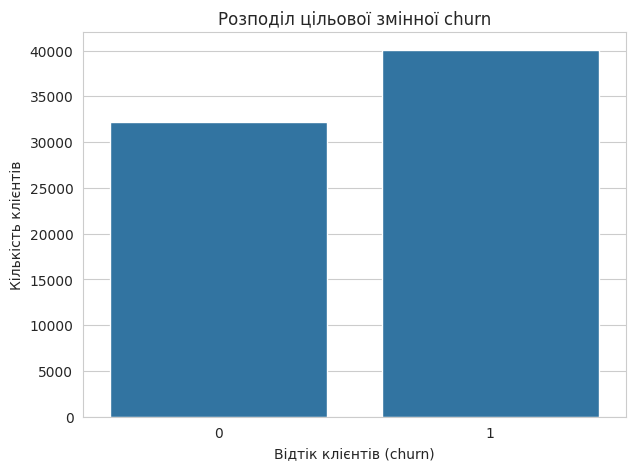

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churn")

plt.title("Розподіл цільової змінної churn")
plt.xlabel("Відтік клієнтів (churn)")
plt.ylabel("Кількість клієнтів")

plt.show()

#### Висновки за результатами візуалізації

Побудована діаграма підтверджує, що в наборі даних дещо переважають клієнти з `churn = 1`, тобто записи, позначені як відтік клієнтів.

Кількість таких записів становить 40 050 (55,41%), тоді як кількість записів із `churn = 0` дорівнює 32 224 (44,59%).

Отже, розподіл цільової змінної є відносно збалансованим, хоча частка клієнтів із відтоком дещо більша. Під час подальшого навчання та оцінювання моделей враховуватимемо не лише Accuracy, а й Precision, Recall та F1-score.

### 4.11. Аналіз кількості унікальних значень

На цьому етапі дослідимо кількість унікальних значень у кожному стовпці набору даних.

Цей аналіз допоможе визначити, які ознаки мають невелику кількість можливих значень, а які містять багато різних значень. Також він дасть змогу додатково перевірити структуру цільової змінної та ідентифікатора клієнта.

Отримані результати будуть використані для кращого розуміння даних перед подальшим дослідницьким аналізом і підготовкою до машинного навчання.

In [ ]:


unique_counts = df.nunique()


unique_summary = pd.DataFrame({
    "Кількість унікальних значень": unique_counts,
    "Кількість усіх записів": len(df)
})

unique_summary


,Кількість унікальних значень,Кількість усіх записів
id,72274,72274
is_tv_subscriber,2,72274
is_movie_package_subscriber,2,72274
subscription_age,1110,72274
bill_avg,179,72274
reamining_contract,247,72274
service_failure_count,19,72274
download_avg,2856,72274
upload_avg,802,72274
download_over_limit,8,72274


#### Висновки щодо кількості унікальних значень

Аналіз показав, що набір даних містить ознаки з різною кількістю унікальних значень.

Стовпці `is_tv_subscriber` та `is_movie_package_subscriber` мають по два унікальні значення, оскільки відображають наявність або відсутність відповідної підписки. Цільова змінна `churn` також має два значення: `0` і `1`, що підтверджує її бінарний характер.

Стовпець `id` містить 72 274 унікальні значення, тобто кожен запис має власний ідентифікатор. Цю ознаку не використовуватимемо як вхідну характеристику під час навчання моделей.

Інші ознаки мають різну кількість унікальних значень і відображають характеристики клієнтів, їхні рахунки та використання послуг.

Отримані результати допомагають краще зрозуміти структуру набору даних і підготуватися до подальшого аналізу розподілу ознак.

### 4.12. Аналіз розподілу числових ознак

Для дослідження характеристик клієнтів побудуємо гістограми основних числових ознак.

Гістограми допоможуть оцінити розподіл значень, визначити діапазони, у яких зосереджена більшість спостережень, а також виявити ознаки з асиметричним розподілом і потенційно аномальними значеннями.

Для загального огляду розглянемо тривалість користування послугою, середній рахунок, кількість збоїв обслуговування, середній обсяг завантаження та передавання даних.

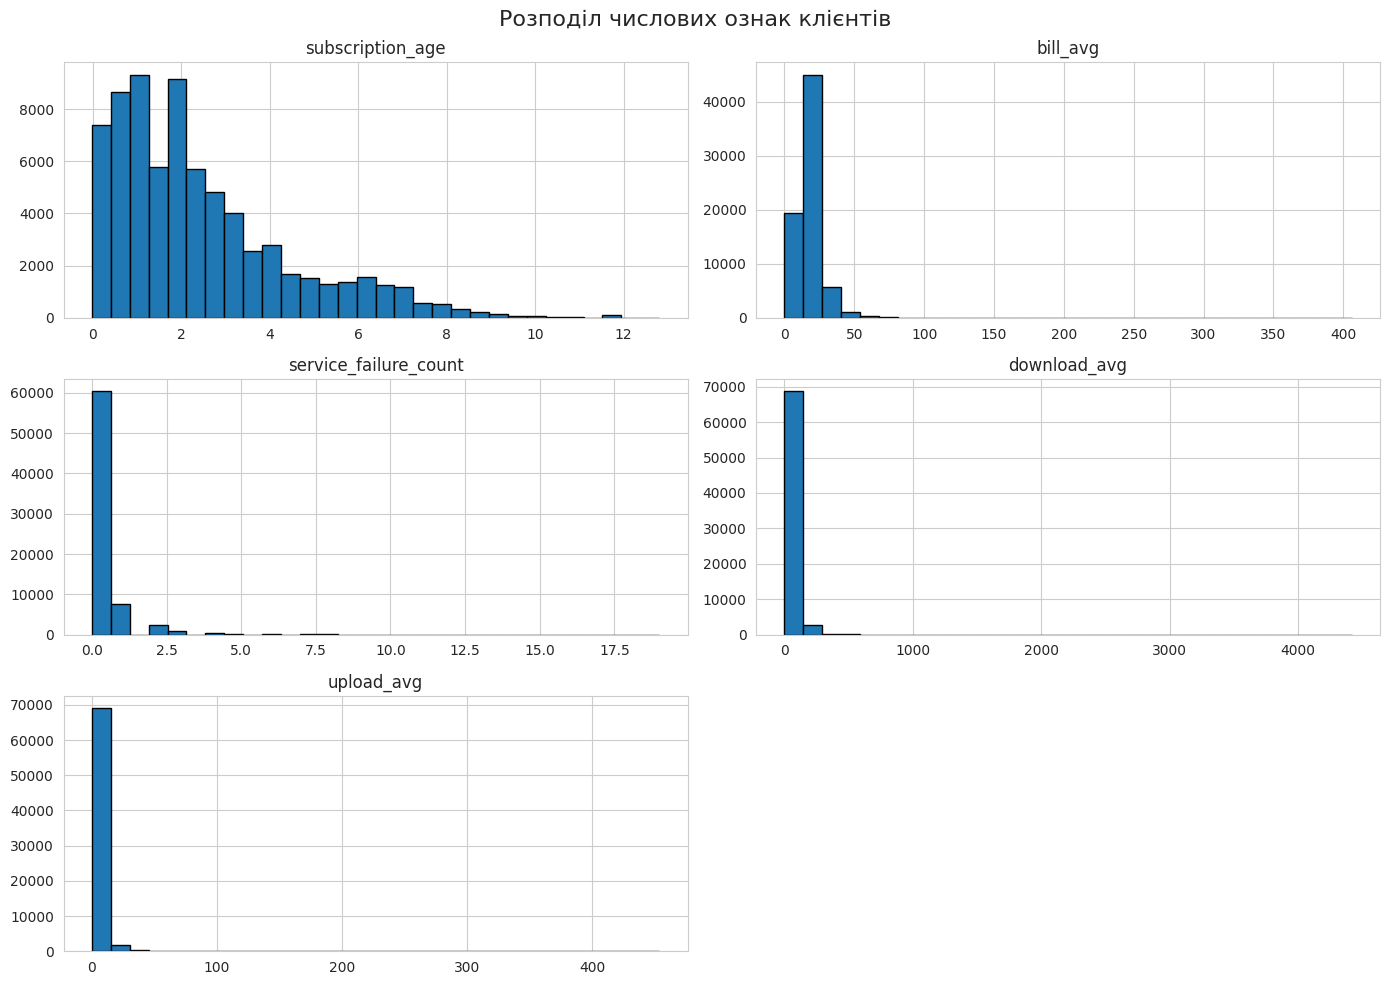

In [ ]:

# Вибираємо числові ознаки для аналізу
numeric_columns = [
    "subscription_age",
    "bill_avg",
    "service_failure_count",
    "download_avg",
    "upload_avg"
]

# Будуємо гістограми для вибраних ознак
df[numeric_columns].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Розподіл числових ознак клієнтів", fontsize=16)
plt.tight_layout()
plt.show()


#### Висновки за результатами аналізу розподілу числових ознак

Гістограми дають змогу оцінити розподіл основних числових характеристик клієнтів телекомунікаційної компанії.

Ознаки `subscription_age`, `bill_avg`, `service_failure_count`, `download_avg` та `upload_avg` мають різні діапазони значень і особливості розподілу.

За результатами попереднього статистичного аналізу в ознаках `bill_avg`, `download_avg` та `upload_avg` спостерігаються значення, які суттєво перевищують відповідні медіани. Це може свідчити про асиметрію розподілів і наявність потенційно аномальних спостережень.

Виявлені особливості необхідно врахувати під час підготовки даних до машинного навчання. Самі по собі великі значення не є достатньою підставою для видалення записів — спочатку потрібно оцінити їхню природу та вплив на моделі.

### 4.13. Аналіз кількості перевищень ліміту завантаження

Ознака `download_over_limit` відображає кількість перевищень ліміту завантаження даних клієнтом.

Для дослідження розподілу цієї ознаки побудуємо стовпчикову діаграму, яка покаже кількість клієнтів для кожного значення. Це допоможе визначити, які значення трапляються найчастіше, та підготуватися до подальшого аналізу зв'язку між використанням ліміту й відтоком клієнтів.

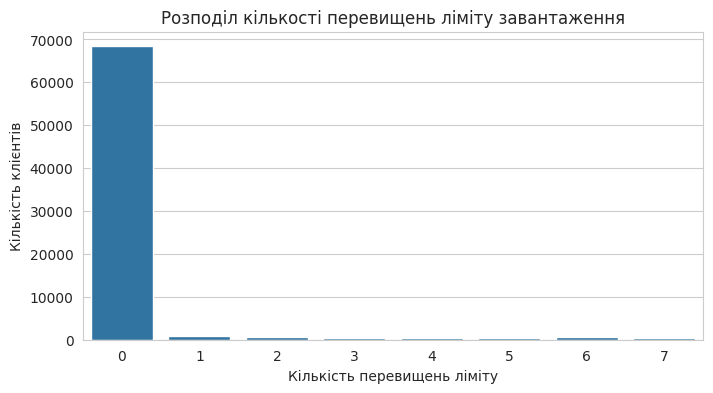

In [ ]:

plt.figure(figsize=(8, 4))

sns.countplot(data=df, x="download_over_limit")

plt.title("Розподіл кількості перевищень ліміту завантаження")
plt.xlabel("Кількість перевищень ліміту")
plt.ylabel("Кількість клієнтів")

plt.show()


#### Висновки щодо розподілу `download_over_limit`

Стовпчикова діаграма відображає кількість клієнтів для кожного значення ознаки `download_over_limit`.

Оскільки ця ознака має обмежену кількість унікальних значень, стовпчикова діаграма дає змогу порівняти частоту їх появи в наборі даних.

Розподіл цієї ознаки допомагає краще зрозуміти особливості використання послуг клієнтами. Щоб визначити, чи пов'язана кількість перевищень ліміту з відтоком, надалі необхідно порівняти цю ознаку з цільовою змінною `churn`.

### 4.14. Аналіз зв’язку між ознаками та відтоком клієнтів

На попередніх етапах ми дослідили структуру набору даних, пропущені значення, розподіл цільової змінної та основних характеристик клієнтів.

Тепер проаналізуємо, як окремі характеристики клієнтів пов’язані з відтоком. Для цього порівняємо значення ознак у двох групах: клієнтів, які залишилися (`churn = 0`), і клієнтів, які пішли (`churn = 1`).

Такий аналіз допоможе виявити можливі закономірності та визначити, які ознаки варто врахувати під час побудови моделей машинного навчання.

Важливо: наявність зв’язку між ознакою та відтоком не означає, що ця ознака безпосередньо спричиняє відтік.

#### 4.14.1. Порівняння середніх значень ознак залежно від відтоку

Для попереднього аналізу порівняємо середні значення числових характеристик клієнтів залежно від значення цільової змінної churn.

Це дасть змогу побачити, чи є відмінності між клієнтами, які залишилися користуватися послугами компанії, та клієнтами, які припинили користування послугами.

Порівняння середніх значень є початковим етапом дослідження. Воно допомагає виявити можливі закономірності, але саме по собі не доводить наявності причинно-наслідкового зв’язку.

In [ ]:

features_to_compare = [
    "subscription_age",
    "bill_avg",
    "reamining_contract",
    "service_failure_count",
    "download_avg",
    "upload_avg",
    "download_over_limit"
]


churn_comparison = df.groupby("churn")[features_to_compare].mean().T


churn_comparison.columns = [
    "Клієнти, які залишилися (churn=0)",
    "Клієнти, які пішли (churn=1)"
]


churn_comparison.round(2)

,"Клієнти, які залишилися (churn=0)","Клієнти, які пішли (churn=1)"
subscription_age,2.73,2.23
bill_avg,19.25,18.69
reamining_contract,1.07,0.18
service_failure_count,0.25,0.29
download_avg,64.88,26.84
upload_avg,5.98,2.77
download_over_limit,0.03,0.35


#### Висновки за результатами порівняння середніх значень

Порівняння середніх значень числових ознак виявило відмінності між клієнтами, які залишилися користуватися послугами компанії, та клієнтами, які припинили користування послугами.

Клієнти, які залишилися, мають вищі середні значення тривалості користування послугою (`subscription_age`), залишку контракту (`reamining_contract`), середнього обсягу завантаження (`download_avg`) та передавання даних (`upload_avg`).

Середнє значення кількості збоїв обслуговування (`service_failure_count`) дещо вище серед клієнтів, які пішли. Водночас середні значення рахунку (`bill_avg`) у двох групах відрізняються незначно.

Особливо помітна різниця для ознаки `download_over_limit`: середня кількість перевищень ліміту в групі клієнтів, які пішли, становить 0,35, тоді як у групі клієнтів, які залишилися, — 0,03.

Отримані результати свідчать, що характеристики користування послугами та стан контракту можуть бути корисними для прогнозування відтоку. Ці закономірності необхідно додатково перевірити під час побудови та оцінювання моделей машинного навчання.

Варто враховувати, що в ознаці `reamining_contract` є значна кількість пропущених значень, а тому її середні значення розраховані лише за наявними даними. Виявлені відмінності не доводять причинно-наслідкового зв’язку між характеристиками клієнтів і відтоком.

#### 4.14.2. Аналіз підписок і перевищень ліміту залежно від відтоку

Додатково дослідимо зв’язок між відтоком клієнтів, наявністю підписки на телевізійні послуги, підпискою на пакет із фільмами та кількістю перевищень ліміту завантаження.

Для цього порівняємо середні значення зазначених ознак у двох групах клієнтів: тих, які залишилися (`churn = 0`), і тих, які пішли (`churn = 1`).

Для бінарних ознак `is_tv_subscriber` та `is_movie_package_subscriber` середнє значення відповідає частці клієнтів, які мають відповідну підписку. Для ознаки `download_over_limit` середнє значення показує середню кількість перевищень ліміту в кожній групі.

In [ ]:
df.groupby("churn")[[
    "is_tv_subscriber",
    "is_movie_package_subscriber",
    "download_over_limit"
]].mean().round(3)

,is_tv_subscriber,is_movie_package_subscriber,download_over_limit
churn,,,
0,0.957,0.496,0.032
1,0.701,0.205,0.349


#### Висновки щодо підписок і перевищень ліміту

Порівняння характеристик клієнтів залежно від значення цільової змінної churn виявило відмінності між двома групами.

Серед клієнтів, які залишилися користуватися послугами компанії, телевізійну підписку мають 95,7%, тоді як серед клієнтів, які пішли, — 70,1%.

Подібна закономірність спостерігається для підписки на пакет із фільмами: її мають 49,6% клієнтів, які залишилися, та 20,5% клієнтів, які пішли.

Також середня кількість перевищень ліміту завантаження в групі клієнтів, які пішли, становить 0,349, тоді як у групі клієнтів, які залишилися, — 0,032.

Отримані результати вказують на можливий зв’язок між наявністю підписок, використанням послуг і відтоком клієнтів. Ці ознаки доцільно зберегти для подальшого моделювання та оцінити їхню корисність за допомогою метрик машинного навчання.

Водночас виявлені відмінності не доводять, що відсутність підписок або перевищення ліміту безпосередньо спричиняють відтік.

#### 4.14.3. Кореляційний аналіз ознак

Для дослідження взаємозв’язків між числовими характеристиками клієнтів побудуємо кореляційну матрицю.

Кореляція показує напрямок і силу лінійного зв’язку між двома числовими змінними. Значення, близькі до 1, свідчать про позитивний зв’язок, значення, близькі до -1, — про негативний, а значення поблизу 0 — про слабкий лінійний зв’язок.

Особливу увагу приділимо зв’язкам між ознаками та цільовою змінною `churn`. Це допоможе попередньо оцінити, які характеристики можуть бути корисними для прогнозування відтоку. Кореляція сама по собі не доводить причинно-наслідкового зв’язку.

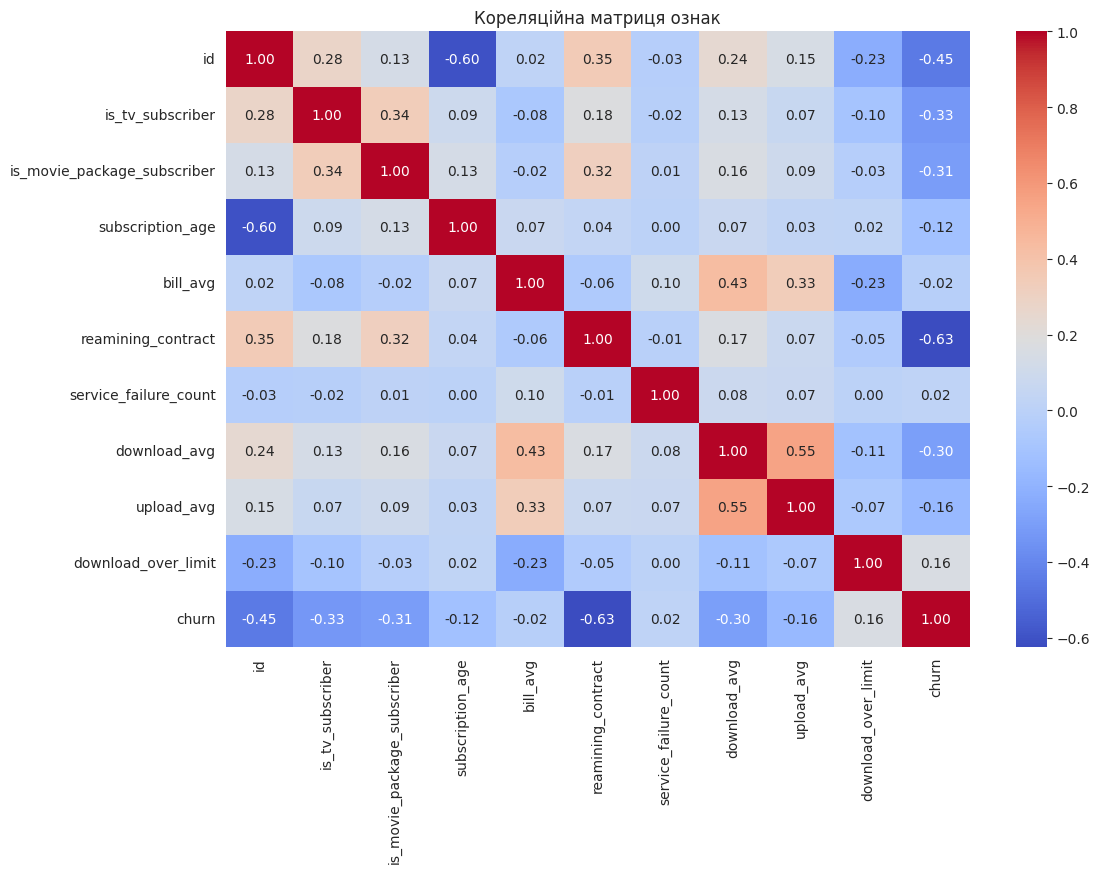

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Кореляційна матриця ознак")
plt.show()

#### Висновки за результатами кореляційного аналізу

Кореляційний аналіз допоміг оцінити лінійні взаємозв’язки між характеристиками клієнтів і цільовою змінною churn.

Найсильніший від’ємний зв’язок із churn серед досліджених ознак має `reamining_contract` (−0,625). Це означає, що більші значення залишку контракту пов’язані з меншою часткою клієнтів, які припинили користуватися послугами. Водночас у цій ознаці є значна кількість пропущених значень, що необхідно врахувати під час підготовки даних.

Ознаки `is_tv_subscriber` (−0,328), `is_movie_package_subscriber` (−0,307) та `download_avg` (−0,298) також мають помітний від’ємний лінійний зв’язок із цільовою змінною.

Ознака `download_over_limit` має слабкий позитивний зв’язок із churn (0,158). Для `service_failure_count` (0,022) і `bill_avg` (−0,021) лінійний зв’язок із цільовою змінною дуже слабкий.

Кореляцію ознаки `id` (−0,451) не слід інтерпретувати як змістовний зв’язок із відтоком, оскільки це унікальний ідентифікатор клієнта. Його буде виключено з ознак, що використовуються для навчання моделі.

Отримані результати є попередніми й допомагають зрозуміти структуру даних. Остаточну корисність ознак потрібно оцінити під час навчання моделей машинного навчання за допомогою відповідних метрик якості.

## 5. Підготовка даних до машинного навчання

Після проведення дослідницького аналізу необхідно підготувати дані для побудови моделей машинного навчання.

На цьому етапі визначимо цільову змінну та ознаки, які використовуватимуться для прогнозування відтоку клієнтів. Також перевіримо пропущені значення, виключимо технічний ідентифікатор клієнта та підготуємо дані до подальшого навчання й оцінювання моделей.

Для коректного оцінювання якості моделі спочатку розділимо дані на навчальну та тестову вибірки. Параметри попередньої обробки навчатимуться лише на навчальній вибірці, щоб уникнути витоку інформації з тестових даних.

### 5.1. Перевірка пропущених значень

Перед підготовкою даних до машинного навчання повторно перевіримо наявність пропущених значень у наборі даних.

Це допоможе визначити, які ознаки потребують попередньої обробки. На цьому етапі ми лише аналізуємо пропуски, не видаляючи рядків і не змінюючи наявних значень.

In [ ]:

missing_summary = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Відсоток пропусків": (df.isnull().mean() * 100).round(2)
})


missing_summary[missing_summary["Кількість пропусків"] > 0]

,Кількість пропусків,Відсоток пропусків
reamining_contract,21572,29.85
download_avg,381,0.53
upload_avg,381,0.53


#### Висновки щодо пропущених значень

Перевірка набору даних виявила пропущені значення у трьох ознаках: `reamining_contract`, `download_avg` та `upload_avg`.

Найбільша кількість пропусків спостерігається в ознаці `reamining_contract` — приблизно 29,85% записів. В ознаках `download_avg` та `upload_avg` частка пропусків становить приблизно 0,53%.

Видаляти всі записи з пропущеними значеннями недоцільно, оскільки це може призвести до втрати значної частини даних. Тому на наступних етапах пропуски буде оброблено за допомогою методів попередньої обробки даних перед навчанням моделей машинного навчання.

### 5.2. Визначення ознак і цільової змінної

Для побудови моделі машинного навчання необхідно відокремити характеристики клієнтів від цільової змінної, яку потрібно спрогнозувати.

У нашому проєкті цільовою змінною є `churn`, яка показує, чи відбувся відтік клієнта:

- `0` — клієнт залишився користуватися послугами компанії;
- `1` — клієнт припинив користуватися послугами компанії.

Усі інші придатні для прогнозування характеристики використаємо як вхідні ознаки. Стовпець `id` виключимо, оскільки він є унікальним ідентифікатором клієнта, а не характеристикою його поведінки.

In [ ]:

X = df.drop(columns=["churn", "id"])


y = df["churn"]


print("Розмір таблиці ознак X:", X.shape)
print("Розмір цільової змінної y:", y.shape)


print("\nОзнаки для навчання моделі:")
print(X.columns.tolist())

Розмір таблиці ознак X: (72274, 9)
Розмір цільової змінної y: (72274,)

Ознаки для навчання моделі:
['is_tv_subscriber', 'is_movie_package_subscriber', 'subscription_age', 'bill_avg', 'reamining_contract', 'service_failure_count', 'download_avg', 'upload_avg', 'download_over_limit']


#### Висновки щодо визначення ознак і цільової змінної

Для побудови моделі визначено дев’ять вхідних ознак, які описують характеристики клієнтів, використання послуг і стан контракту.

Цільовою змінною обрано `churn`, яка відображає наявність або відсутність відтоку клієнта. Технічний ідентифікатор `id` виключено з вхідних ознак, оскільки він не є змістовною характеристикою клієнта.

Після розділення даних отримано 72 274 записи для ознак і відповідну кількість значень цільової змінної. На наступному етапі дані буде розділено на навчальну та тестову вибірки для підготовки й оцінювання моделей машинного навчання.

### 5.3. Розділення даних на навчальну та тестову вибірки

Для побудови та оцінювання моделей машинного навчання розділимо набір даних на навчальну й тестову вибірки.

Навчальна вибірка використовуватиметься для того, щоб модель навчилася знаходити закономірності між характеристиками клієнтів і відтоком. Тестова вибірка дасть змогу оцінити якість прогнозування на даних, які модель не використовувала під час навчання.

Для цього використаємо функцію `train_test_split` із бібліотеки `scikit-learn`. Виділимо 80% даних для навчання та 20% для тестування.

Параметр `stratify=y` збереже приблизно однакове співвідношення класів `churn` у навчальній і тестовій вибірках. Параметр `random_state=42` забезпечить відтворюваність результату.

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


print("Розмір навчальної вибірки X_train:", X_train.shape)
print("Розмір тестової вибірки X_test:", X_test.shape)

print("Розмір навчальної цільової змінної y_train:", y_train.shape)
print("Розмір тестової цільової змінної y_test:", y_test.shape)

Розмір навчальної вибірки X_train: (57819, 9)
Розмір тестової вибірки X_test: (14455, 9)
Розмір навчальної цільової змінної y_train: (57819,)
Розмір тестової цільової змінної y_test: (14455,)


#### Висновки щодо розділення даних

Набір даних було розділено на навчальну та тестову вибірки у співвідношенні 80% до 20%.

Навчальна вибірка містить 57 819 записів, а тестова — 14 455 записів. Для обох вибірок сформовано дев’ять вхідних ознак і відповідні значення цільової змінної `churn`.

Завдяки параметру `stratify=y` збережено приблизно однакове співвідношення класів у навчальній і тестовій вибірках. Тестові дані не використовуватимуться для навчання моделей і допоможуть оцінити їхню здатність прогнозувати відтік для нових спостережень.

### 5.4. Створення конвеєра попередньої обробки даних

Перед навчанням моделей машинного навчання необхідно перевірити типи ознак і налаштувати обробку пропущених значень та масштабування даних.

Спочатку перевіримо, чи є в наборі текстові категоріальні ознаки. Потім створимо конвеєр попередньої обробки, який автоматично заповнюватиме пропущені значення медіаною та масштабуватиме числові ознаки.

Параметри попередньої обробки визначатимуться лише за навчальними даними, щоб уникнути витоку інформації з тестової вибірки.

In [ ]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Категоріальні ознаки:", categorical_columns)

if len(categorical_columns) == 0:
    print("Категоріальних ознак у текстовому форматі немає.")

Категоріальні ознаки: []
Категоріальних ознак у текстовому форматі немає.


In [ ]:
numeric_features = X.columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features)
    ]
)

print("Кількість ознак для обробки:", len(numeric_features))
print("Ознаки:", numeric_features)

Кількість ознак для обробки: 9
Ознаки: ['is_tv_subscriber', 'is_movie_package_subscriber', 'subscription_age', 'bill_avg', 'reamining_contract', 'service_failure_count', 'download_avg', 'upload_avg', 'download_over_limit']


#### Висновки щодо створення конвеєра попередньої обробки

У ході підготовки даних перевірено типи ознак і визначено, що категоріальні ознаки в текстовому форматі відсутні. Бінарні ознаки підписок уже представлені числовими значеннями 0 і 1, тому додаткове кодування не потрібне.

Створено конвеєр попередньої обробки, який поєднує заповнення пропущених значень медіаною та масштабування числових ознак за допомогою `StandardScaler`.

Конвеєр буде використовуватися під час навчання моделей машинного навчання. Параметри попередньої обробки визначатимуться лише на навчальній вибірці, що допоможе уникнути витоку інформації з тестових даних.

### 6. Розробка моделі

На цьому етапі побудуємо та порівняємо кілька моделей машинного навчання для прогнозування відтоку клієнтів телекомунікаційної компанії.
Для дослідження використаємо три алгоритми класифікації:
- Logistic Regression — логістична регресія;
- Decision Tree — дерево рішень;
- Linear SVM — лінійний метод опорних векторів.
Кожен із цих алгоритмів використовує власний підхід до класифікації клієнтів. Їх порівняння допоможе визначити, який алгоритм краще прогнозує відтік клієнтів.
Якість моделей оцінимо за метриками Accuracy, Precision, Recall та F1-score. Також застосуємо крос-валідацію та підбір параметрів, щоб оцінити стабільність моделей і знайти налаштування, які покращують результати.

### 6.1. Навчання моделі логістичної регресії
Логістична регресія (Logistic Regression) — це алгоритм машинного навчання, який використовується для розв’язання задач класифікації.
У нашому проєкті модель прогнозуватиме, чи відбудеться відтік клієнта телекомунікаційної компанії. Цільова змінна churn має два можливі значення: 0 — відтік не відбувся, 1 — відтік відбувся.
Для навчання моделі використаємо підготовлені навчальні дані X_train та y_train. Попередню обробку виконаємо за допомогою створеного раніше конвеєра preprocessor, який заповнює пропущені значення медіаною та масштабує ознаки.
Після цього навчимо модель і перевіримо, наскільки добре вона прогнозує відтік клієнтів на тестових даних.

In [ ]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Модель логістичної регресії успішно навчена!")

Модель логістичної регресії успішно навчена!


### 6.2. Оцінювання моделі логістичної регресії
Після навчання моделі необхідно оцінити якість її прогнозів на тестовій вибірці. Для цього використаємо дані X_test, які модель не бачила під час навчання.
Оцінимо модель за чотирма метриками:
- Accuracy — частка правильних прогнозів серед усіх прогнозів.
- Precision — частка клієнтів із прогнозованим відтоком, у яких відтік справді відбувся.
- Recall — частка клієнтів, у яких відтік відбувся і яких модель правильно виявила.
- F1-score — узагальнена оцінка Precision та Recall.

In [ ]:

y_pred_logistic = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic, zero_division=0)
recall = recall_score(y_test, y_pred_logistic, zero_division=0)
f1 = f1_score(y_test, y_pred_logistic, zero_division=0)

print("Результати Logistic Regression:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

Результати Logistic Regression:
Accuracy:  0.8360
Precision: 0.8332
Recall:    0.8803
F1-score:  0.8561


### Висновки щодо логістичної регресії
У результаті навчання логістичної регресії отримано Accuracy 83,60%, Precision 83,32%, Recall 88,03% та F1-score 85,61%.
Модель демонструє здатність виявляти клієнтів, схильних до відтоку. Значення Recall 88,03% свідчить про те, що модель правильно виявляє більшість клієнтів, у яких відбувся відтік.
Водночас для визначення найкращого алгоритму необхідно порівняти ці результати з іншими моделями машинного навчання. Тому надалі навчимо дерево рішень і лінійний метод опорних векторів та оцінимо їх за тими самими метриками.

### 6.3. Навчання моделі дерева рішень
Дерево рішень (Decision Tree) — це алгоритм машинного навчання, який використовує послідовність умов для класифікації об'єктів.
У нашому проєкті модель аналізуватиме характеристики клієнтів і визначатиме, до якого класу вони належать: клієнти без відтоку (0) чи клієнти з відтоком (1).
Для навчання використаємо навчальну вибірку X_train та y_train. Створимо конвеєр, який заповнюватиме пропущені значення медіаною, після чого дерево рішень навчатиметься на підготовлених даних.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ))
])

tree_model.fit(X_train, y_train)

print("Модель дерева рішень успішно навчена!")

Модель дерева рішень успішно навчена!


### 6.4. Оцінювання моделі дерева рішень
Після навчання дерева рішень оцінимо його прогнози на тестовій вибірці, яка не використовувалася під час навчання.
Для оцінювання застосуємо Accuracy, Precision, Recall та F1-score. Це дасть змогу порівняти дерево рішень із логістичною регресією за однаковими критеріями.

In [ ]:

y_pred_tree = tree_model.predict(X_test)


accuracy_tree = accuracy_score(y_test, y_pred_tree)
precision_tree = precision_score(
    y_test, y_pred_tree, zero_division=0
)
recall_tree = recall_score(
    y_test, y_pred_tree, zero_division=0
)
f1_tree = f1_score(
    y_test, y_pred_tree, zero_division=0
)


print("Результати Decision Tree:")
print(f"Accuracy:  {accuracy_tree:.4f}")
print(f"Precision: {precision_tree:.4f}")
print(f"Recall:    {recall_tree:.4f}")
print(f"F1-score:  {f1_tree:.4f}")

Результати Decision Tree:
Accuracy:  0.9364
Precision: 0.9514
Recall:    0.9328
F1-score:  0.9420


### Висновки щодо дерева рішень
У результаті навчання моделі Decision Tree отримано Accuracy 93,64%, Precision 95,14%, Recall 93,28% та F1-score 94,20%.
За всіма чотирма метриками дерево рішень показало кращі результати, ніж логістична регресія. Особливо важливим є значення Recall 93,28%, яке свідчить про здатність моделі виявляти більшість клієнтів, у яких відбувається відтік.

### 6.5. Навчання моделі Linear SVM
Linear SVM (Linear Support Vector Machine) — це алгоритм машинного навчання, який використовується для класифікації. Він шукає межу, що найкраще розділяє об'єкти різних класів.
У нашому проєкті модель визначатиме, чи належить клієнт до класу без відтоку (0) або до класу з відтоком (1).
Для навчання використаємо X_train та y_train. Попередню обробку даних виконаємо за допомогою створеного конвеєра preprocessor. Для Linear SVM масштабування ознак особливо важливе, оскільки алгоритм чутливий до їхніх масштабів.

In [ ]:
from sklearn.svm import LinearSVC

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

print("Модель Linear SVM успішно навчена!")

Модель Linear SVM успішно навчена!


### 6.6. Оцінювання моделі Linear SVM
Після навчання моделі Linear SVM перевіримо якість її прогнозів на тестовій вибірці.
Для оцінювання використаємо метрики Accuracy, Precision, Recall та F1-score. Це дозволить порівняти лінійний метод опорних векторів із логістичною регресією та деревом рішень.

In [ ]:

y_pred_svm = svm_model.predict(X_test)


accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(
    y_test, y_pred_svm, zero_division=0
)
recall_svm = recall_score(
    y_test, y_pred_svm, zero_division=0
)
f1_svm = f1_score(
    y_test, y_pred_svm, zero_division=0
)


print("Результати Linear SVM:")
print(f"Accuracy:  {accuracy_svm:.4f}")
print(f"Precision: {precision_svm:.4f}")
print(f"Recall:    {recall_svm:.4f}")
print(f"F1-score:  {f1_svm:.4f}")

Результати Linear SVM:
Accuracy:  0.8354
Precision: 0.8254
Recall:    0.8916
F1-score:  0.8572


### 6.7. Порівняння результатів моделей
Для визначення найкращого алгоритму порівняємо результати логістичної регресії, дерева рішень і Linear SVM на тестовій вибірці. Для всіх моделей використано однакові метрики оцінювання.

| Метрика | Logistic Regression | Decision Tree | Linear SVM |
|---|---:|---:|---:|
| Accuracy | 83,60% | 93,64% | 83,54% |
| Precision | 83,32% | 95,14% | 82,54% |
| Recall | 88,03% | 93,28% | 89,16% |
| F1-score | 85,61% | 94,20% | 85,72% |

За результатами оцінювання на тестовій вибірці дерево рішень показало найвищі значення всіх чотирьох метрик. Його F1-score становить 94,20%, тоді як у логістичної регресії — 85,61%, а в Linear SVM — 85,72%.
Отже, на цьому етапі дерево рішень є найкращою моделлю серед трьох досліджених алгоритмів. Проте перед остаточним вибором необхідно провести крос-валідацію, щоб перевірити стабільність результатів і ризик перенавчання.

### 6.8. Крос-валідація моделей
Крос-валідація — це метод оцінювання якості моделі, за якого навчальні дані поділяються на кілька частин. Модель навчається на одних частинах даних і перевіряється на іншій. Процес повторюється кілька разів, після чого результати усереднюються.

У нашому проєкті використаємо п'ятиблокову крос-валідацію (5-fold cross-validation). Навчальна вибірка буде поділена на п'ять частин. На кожній ітерації одна частина використовуватиметься для перевірки, а решта чотири — для навчання.

Для порівняння моделей використовуватимемо метрику F1-score, яка враховує Precision і Recall. Попередня обробка даних виконуватиметься всередині конвеєра, щоб уникнути витоку інформації між частинами даних.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Linear SVM": svm_model
}


cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Модель": name,
        "Середній F1-score": scores["test_score"].mean(),
        "Стандартне відхилення": scores["test_score"].std()
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df = cv_results_df.sort_values(
    by="Середній F1-score",
    ascending=False
)

print("Результати 5-блокової крос-валідації:")
display(cv_results_df.round(4))

Результати 5-блокової крос-валідації:


,Модель,Середній F1-score,Стандартне відхилення
1,Decision Tree,0.9422,0.0032
2,Linear SVM,0.8553,0.0046
0,Logistic Regression,0.8551,0.0042


**Висновок за результатами крос-валідації**

За результатами п'ятиблокової крос-валідації найкращий середній F1-score показала модель Decision Tree — 0.9422. Стандартне відхилення становить 0.0032, що свідчить про стабільні результати моделі на різних частинах навчальних даних.

Моделі Linear SVM та Logistic Regression показали нижчі результати: середній F1-score становить 0.8553 та 0.8551 відповідно.

Отже, на цьому етапі Decision Tree є найперспективнішою моделлю для прогнозування відтоку клієнтів. Наступним кроком буде підбір її гіперпараметрів для пошуку потенційно кращих налаштувань.

### 6.9. Підбір гіперпараметрів моделі Decision Tree

Гіперпараметри — це налаштування моделі, які задаються до початку навчання. Вони впливають на складність дерева рішень і його здатність правильно класифікувати клієнтів.

Для покращення моделі використаємо GridSearchCV. Цей інструмент автоматично перевіряє різні комбінації параметрів за допомогою крос-валідації та допомагає знайти найкращий варіант.

Перевіримо такі параметри:

- `max_depth` — максимальна глибина дерева;
- `min_samples_split` — мінімальна кількість зразків, необхідна для розділення вузла;
- `min_samples_leaf` — мінімальна кількість зразків у листі дерева.

Для вибору найкращої комбінації використовуватимемо F1-score.


In [ ]:
from sklearn.model_selection import GridSearchCV


param_grid = {
    "classifier__max_depth": [8, 10, 12, 15],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5]
}


grid_search = GridSearchCV(
    estimator=tree_model,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)


grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкращий середній F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Найкращі параметри:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}

Найкращий середній F1-score:
0.9435


**Висновок за результатами підбору гіперпараметрів**

Для моделі Decision Tree було виконано підбір гіперпараметрів за допомогою GridSearchCV із п'ятиблоковою крос-валідацією. Було перевірено 36 комбінацій параметрів, загалом виконано 180 навчань і перевірок моделі.

Найкращими виявилися такі параметри:

- `max_depth = 10` — максимальна глибина дерева;
- `min_samples_leaf = 5` — мінімальна кількість зразків у листі;
- `min_samples_split = 2` — мінімальна кількість зразків для розділення вузла.

Найкращий середній F1-score становить 0.9435, тоді як до підбору параметрів він дорівнював 0.9422. Отже, вдалося трохи покращити результат моделі. Наступним етапом буде оцінювання налаштованої моделі на тестовій вибірці.


### 6.10. Оцінювання налаштованої моделі на тестових даних

Після підбору гіперпараметрів необхідно перевірити якість найкращої моделі Decision Tree на тестовій вибірці.

Для цього використаємо модель із найкращими знайденими параметрами та обчислимо метрики Accuracy, Precision, Recall і F1-score.

Тестова вибірка не використовувалася під час навчання моделі та підбору гіперпараметрів, тому результати допоможуть оцінити її здатність прогнозувати відтік клієнтів на нових даних.

In [ ]:

best_tree_model = grid_search.best_estimator_


y_pred_best_tree = best_tree_model.predict(X_test)


accuracy_best = accuracy_score(y_test, y_pred_best_tree)
precision_best = precision_score(
    y_test, y_pred_best_tree, zero_division=0
)
recall_best = recall_score(
    y_test, y_pred_best_tree, zero_division=0
)
f1_best = f1_score(
    y_test, y_pred_best_tree, zero_division=0
)


print("Результати налаштованої моделі Decision Tree:")
print(f"Accuracy:  {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1-score:  {f1_best:.4f}")

Результати налаштованої моделі Decision Tree:
Accuracy:  0.9372
Precision: 0.9501
Recall:    0.9358
F1-score:  0.9429


### 6.11. Порівняння початкової та налаштованої моделей

На цьому етапі порівняємо початкову модель Decision Tree з моделлю, для якої було підібрано найкращі гіперпараметри за допомогою GridSearchCV.

Порівняння за метриками Accuracy, Precision, Recall і F1-score допоможе оцінити, як змінилися результати після налаштування моделі.


In [ ]:

comparison_tree = pd.DataFrame({
    "Метрика": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Початкова Decision Tree": [
        accuracy_tree,
        precision_tree,
        recall_tree,
        f1_tree
    ],
    "Налаштована Decision Tree": [
        accuracy_best,
        precision_best,
        recall_best,
        f1_best
    ]
})

display(comparison_tree.round(4))

,Метрика,Початкова Decision Tree,Налаштована Decision Tree
0,Accuracy,0.9364,0.9372
1,Precision,0.9514,0.9501
2,Recall,0.9328,0.9358
3,F1-score,0.9420,0.9429


### 6.12. Матриця помилок налаштованої моделі

Матриця помилок (Confusion Matrix) дає змогу детальніше оцінити результати класифікації. Вона показує кількість правильних і помилкових прогнозів для кожного класу.

У нашому проєкті клас 0 означає, що клієнт не залишив компанію, а клас 1 — що клієнт залишив компанію.

Матриця допоможе визначити, скільки клієнтів модель правильно класифікувала та скільки випадків відтоку не змогла виявити.


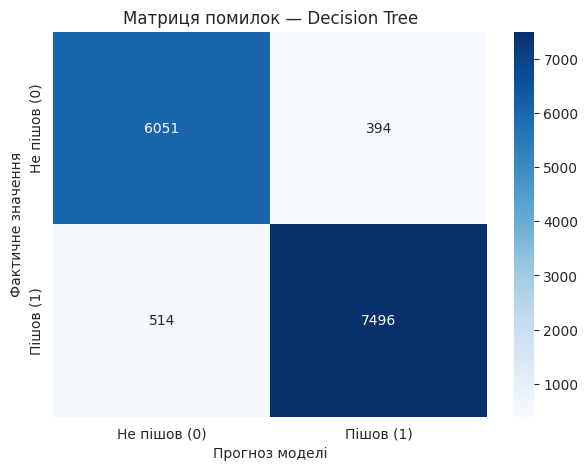

In [ ]:

cm = confusion_matrix(y_test, y_pred_best_tree)


plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не пішов (0)", "Пішов (1)"],
    yticklabels=["Не пішов (0)", "Пішов (1)"]
)

plt.xlabel("Прогноз моделі")
plt.ylabel("Фактичне значення")
plt.title("Матриця помилок — Decision Tree")
plt.show()

**Висновок за результатами матриці помилок**

Матриця помилок показала, що налаштована модель Decision Tree правильно класифікувала 6 051 клієнта, які залишилися з компанією, та 7 496 клієнтів, які пішли.

Водночас модель допустила два типи помилок: для 394 клієнтів помилково спрогнозувала відтік, хоча вони залишилися, а для 514 клієнтів не змогла передбачити фактичний відтік.

Загалом модель правильно класифікувала 13 547 клієнтів із 14 455 тестових записів. Це свідчить про високу якість прогнозування на тестовій вибірці.

Для телекомунікаційної компанії важливо й надалі працювати над зменшенням кількості клієнтів, відтік яких модель не виявляє, щоб своєчасно пропонувати їм заходи утримання.


### 6.13. Підсумковий звіт класифікації

Для детальнішого оцінювання налаштованої моделі Decision Tree використаємо classification report. Він містить основні метрики якості класифікації окремо для кожного класу та їхні узагальнені значення.

Це дасть змогу оцінити, наскільки добре модель визначає клієнтів, які залишаються з компанією, і клієнтів, які припиняють користуватися послугами.


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_best_tree,
        target_names=["Клієнт залишився", "Клієнт пішов"],
        digits=4,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

Клієнт залишився     0.9217    0.9389    0.9302      6445
    Клієнт пішов     0.9501    0.9358    0.9429      8010

        accuracy                         0.9372     14455
       macro avg     0.9359    0.9373    0.9366     14455
    weighted avg     0.9374    0.9372    0.9372     14455



**Висновок за результатами звіту класифікації**

Підсумковий звіт показав, що налаштована модель Decision Tree правильно класифікує 93,72% клієнтів тестової вибірки.

Для класу клієнтів, які пішли, Precision становить 0.9501, Recall — 0.9358, а F1-score — 0.9429. Це означає, що модель добре визначає клієнтів, які припиняють користуватися послугами компанії.

Для класу клієнтів, які залишилися, F1-score становить 0.9302.

Отже, модель демонструє високі результати для обох класів і може бути перспективною основою для системи прогнозування відтоку клієнтів. Перед практичним використанням доцільно додатково перевірити її роботу на нових даних і врахувати бізнес-витрати, пов'язані з помилковими прогнозами.


### 6.14. Аналіз важливості ознак

Для інтерпретації моделі Decision Tree проаналізуємо важливість ознак. Цей показник допомагає визначити, які характеристики найбільше використовуються деревом для розділення клієнтів на класи.

Результати допоможуть зрозуміти, які характеристики пов'язані з прогнозом відтоку. Водночас важливість ознаки не доводить, що саме вона є причиною відтоку клієнта.


,Ознака,Важливість
4,reamining_contract,0.8686
6,download_avg,0.0845
3,bill_avg,0.0210
2,subscription_age,0.0194
1,is_movie_package_subscriber,0.0031
7,upload_avg,0.0018
0,is_tv_subscriber,0.0007
8,download_over_limit,0.0006
5,service_failure_count,0.0003


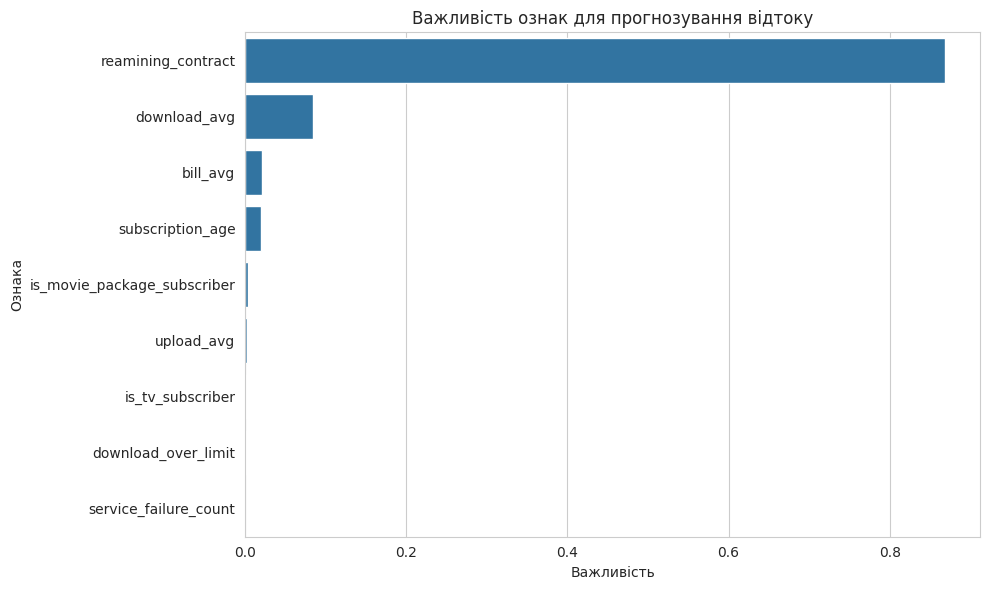

In [ ]:

best_tree = best_tree_model.named_steps["classifier"]


feature_importance = pd.DataFrame({
    "Ознака": X_train.columns,
    "Важливість": best_tree.feature_importances_
})


feature_importance = feature_importance.sort_values(
    by="Важливість",
    ascending=False
)

display(feature_importance.round(4))


plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Важливість",
    y="Ознака"
)
plt.title("Важливість ознак для прогнозування відтоку")
plt.xlabel("Важливість")
plt.ylabel("Ознака")
plt.tight_layout()
plt.show()

**Висновок за результатами аналізу важливості ознак**

Аналіз важливості ознак показав, що найбільший внесок у прогнозування відтоку клієнтів має ознака `reamining_contract` — 0.8686. Друге місце посідає `download_avg` із показником 0.0845.

Менший внесок мають `bill_avg` (0.0210) та `subscription_age` (0.0194). Важливість інших ознак у побудованому дереві рішень є значно меншою.

Отже, модель найбільше спирається на інформацію про залишок терміну контракту. Цей результат може допомогти компанії визначити групи клієнтів, для яких варто додатково дослідити ризик відтоку.

Водночас важливість ознак відображає їхній внесок у рішення конкретної моделі, а не доводить причинно-наслідковий зв'язок. Оскільки `reamining_contract` має дуже високу важливість, варто додатково перевірити якість даних і переконатися, що ця ознака доступна на момент, коли потрібно зробити прогноз.


### 6.15. Перевірка перенавчання моделі

Для оцінювання здатності моделі узагальнювати закономірності порівняємо F1-score на навчальній і тестовій вибірках.

Якщо показники суттєво відрізняються, це може свідчити про перенавчання. Якщо вони близькі, це є ознакою того, що модель демонструє подібну якість на даних, використаних для навчання, і на відкладеній тестовій вибірці.


In [ ]:

y_train_pred_best = best_tree_model.predict(X_train)
y_test_pred_best = best_tree_model.predict(X_test)


f1_train_best = f1_score(
    y_train, y_train_pred_best, zero_division=0
)
f1_test_best = f1_score(
    y_test, y_test_pred_best, zero_division=0
)

print(f"F1-score на навчальних даних: {f1_train_best:.4f}")
print(f"F1-score на тестових даних:   {f1_test_best:.4f}")
print(f"Різниця між показниками:      {f1_train_best - f1_test_best:.4f}")

F1-score на навчальних даних: 0.9483
F1-score на тестових даних:   0.9429
Різниця між показниками:      0.0054


## Загальні висновки

У межах проєкту було досліджено дані клієнтів телекомунікаційної компанії та побудовано моделі машинного навчання для прогнозування відтоку клієнтів.

На етапі дослідницького аналізу даних було перевірено структуру датасету, пропущені значення, розподіл цільової змінної та взаємозв'язки між ознаками.

Для розв'язання задачі класифікації було побудовано та порівняно три моделі: Logistic Regression, Decision Tree та Linear SVM. Найкращі результати показала модель Decision Tree.

За допомогою GridSearchCV було підібрано гіперпараметри моделі. Найкраща комбінація включає максимальну глибину дерева 10, мінімальну кількість зразків у листі 5 та мінімальну кількість зразків для розділення вузла 2.

На тестовій вибірці налаштована модель показала такі результати:

- Accuracy — 0.9372;
- Precision — 0.9501;
- Recall — 0.9358;
- F1-score — 0.9429.

Матриця помилок і звіт класифікації дали змогу детальніше оцінити правильні та помилкові прогнози. Аналіз важливості ознак показав, що найбільший внесок у рішення моделі має ознака `reamining_contract`.

Перевірка різниці між F1-score на навчальній і тестовій вибірках не виявила явних ознак сильного перенавчання.

Таким чином, побудована модель демонструє високу якість прогнозування відтоку клієнтів на наявній тестовій вибірці. Наступним етапом проєкту є інтеграція моделі в застосунок, який дозволить вводити дані нового клієнта, отримувати прогноз імовірності відтоку та переглядати результати у зрозумілому вигляді. Також необхідно підготувати Docker-контейнер і документацію з інструкціями користування.


## 7. Інтеграція та виведення результатів

### 7.1. Збереження навченої моделі

Після навчання та оцінювання моделей необхідно зберегти найкращу модель машинного навчання для подальшого використання у вебзастосунку.

Для збереження моделі використаємо бібліотеку `joblib`. Збережена модель міститиме алгоритм класифікації та етапи попередньої обробки даних, що дозволить застосовувати ті самі перетворення до даних нових клієнтів.

In [ ]:
import joblib

model_path = "/content/telecom_churn_model.joblib"

joblib.dump(best_tree_model, model_path)

print("Модель успішно збережено!")
print("Шлях до файлу:", model_path)

Модель успішно збережено!
Шлях до файлу: /content/telecom_churn_model.joblib


### 7.2. Перевірка збереженої моделі

На цьому етапі перевіримо, чи правильно збереглася навчена модель і чи можна завантажити її з файлу для подальшого використання у вебзастосунку.

In [ ]:
import os
import joblib

model_path = "/content/telecom_churn_model.joblib"

if os.path.exists(model_path):
    loaded_model = joblib.load(model_path)
    print("Модель успішно завантажено!")
    print("Тип моделі:", type(loaded_model).__name__)
else:
    print("Файл моделі не знайдено. Перевір попередній крок.")

Модель успішно завантажено!
Тип моделі: Pipeline


### 7.3. Тестування прогнозу для нового клієнта

На цьому етапі перевіримо роботу збереженої моделі на прикладі нового клієнта. Передамо моделі значення ознак клієнта та отримаємо прогнозований клас і ймовірність відтоку.

In [ ]:

new_customer = pd.DataFrame([{
    "is_tv_subscriber": 1,
    "is_movie_package_subscriber": 0,
    "subscription_age": 2.5,
    "bill_avg": 20,
    "reamining_contract": 1.0,
    "service_failure_count": 0,
    "download_avg": 10,
    "upload_avg": 2,
    "download_over_limit": 0
}])


prediction = loaded_model.predict(new_customer)[0]
churn_probability = loaded_model.predict_proba(new_customer)[0][1]

print("Прогноз:", "Клієнт піде" if prediction == 1 else "Клієнт залишиться")
print(f"Ймовірність відтоку: {churn_probability:.2%}")

Прогноз: Клієнт залишиться
Ймовірність відтоку: 8.18%


### 7.4. Створення інтерфейсу для прогнозування відтоку

Для взаємодії з моделлю машинного навчання буде розроблено вебзастосунок на основі бібліотеки Streamlit. Інтерфейс дозволить вводити характеристики нового клієнта, отримувати прогноз відтоку та переглядати розраховану моделлю ймовірність.

Застосунок також відображатиме результат прогнозування у зрозумілому вигляді, щоб користувач міг оцінити ризик відтоку клієнта.

### 7.5. Створення файлу вебзастосунку

Для реалізації інтерфейсу користувача використаємо бібліотеку Streamlit. Код застосунку буде збережено в окремому файлі `app.py`. Він забезпечуватиме введення характеристик клієнта, передавання даних до навченої моделі та відображення результату прогнозування.

In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib

# Налаштування сторінки
st.set_page_config(
    page_title="Прогнозування відтоку клієнтів",
    page_icon="📊",
    layout="centered"
)

# Завантаження навченої моделі
model = joblib.load("/content/telecom_churn_model.joblib")

# Заголовок і опис
st.title("Прогнозування відтоку клієнтів")

st.write(
    "Введіть характеристики клієнта, щоб оцінити "
    "ймовірність припинення користування послугами."
)

st.info(
    "Заповніть поля нижче та натисніть кнопку прогнозування."
)

Writing /content/app.py


### 7.6. Введення даних нового клієнта

Для отримання прогнозу користувач зможе вводити характеристики нового клієнта через поля вебінтерфейсу. Будуть передбачені числові поля для кількісних показників і перемикачі для бінарних ознак. Введені значення формуватимуть набір даних, сумісний із форматом, на якому навчалася модель.

In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib


st.set_page_config(
    page_title="Прогнозування відтоку клієнтів",
    page_icon="📊",
    layout="centered"
)


model = joblib.load("/content/telecom_churn_model.joblib")


st.title("Прогнозування відтоку клієнтів")
st.write(
    "Введіть характеристики клієнта, щоб оцінити "
    "ймовірність припинення користування послугами."
)

st.info("Заповніть поля нижче.")


st.subheader("Характеристики клієнта")

is_tv_subscriber = st.selectbox(
    "Клієнт має підписку на телебачення?",
    options=[1, 0],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)

is_movie_package_subscriber = st.selectbox(
    "Клієнт має пакет фільмів?",
    options=[1, 0],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)

subscription_age = st.number_input(
    "Тривалість підписки (роки)",
    min_value=0.0,
    value=2.5,
    step=0.5
)

bill_avg = st.number_input(
    "Середній рахунок",
    min_value=0.0,
    value=20.0,
    step=1.0
)

reamining_contract = st.number_input(
    "Термін дії контракту за даними датасету",
    min_value=0.0,
    value=1.0,
    step=0.5,
    help="Введіть значення у форматі, який використовувався в датасеті."
)

service_failure_count = st.number_input(
    "Кількість збоїв сервісу",
    min_value=0,
    value=0,
    step=1
)

download_avg = st.number_input(
    "Середній обсяг завантаження даних",
    min_value=0.0,
    value=10.0,
    step=1.0
)

upload_avg = st.number_input(
    "Середній обсяг передавання даних",
    min_value=0.0,
    value=2.0,
    step=0.5
)

download_over_limit = st.selectbox(
    "Перевищення ліміту завантаження?",
    options=[0, 1],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)

st.write("Введені характеристики готові для прогнозування.")

Overwriting /content/app.py


### 7.7. Прогнозування та візуалізація результатів

Після введення характеристик клієнта користувач зможе запустити прогнозування за допомогою відповідної кнопки. Навчена модель визначатиме прогнозований клас і розраховуватиме ймовірність відтоку. Результат відображатиметься у вигляді текстового повідомлення та графічного індикатора ймовірності.

In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib


st.set_page_config(
    page_title="Прогнозування відтоку клієнтів",
    page_icon="📊",
    layout="centered"
)


model = joblib.load("/content/telecom_churn_model.joblib")


st.title("Прогнозування відтоку клієнтів")
st.write(
    "Введіть характеристики клієнта, щоб оцінити "
    "ймовірність припинення користування послугами."
)

st.info("Заповніть поля нижче.")


st.subheader("Характеристики клієнта")

is_tv_subscriber = st.selectbox(
    "Клієнт має підписку на телебачення?",
    options=[1, 0],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)

is_movie_package_subscriber = st.selectbox(
    "Клієнт має пакет фільмів?",
    options=[1, 0],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)

subscription_age = st.number_input(
    "Тривалість підписки (роки)",
    min_value=0.0,
    value=2.5,
    step=0.5
)

bill_avg = st.number_input(
    "Середній рахунок",
    min_value=0.0,
    value=20.0,
    step=1.0
)

reamining_contract = st.number_input(
    "Термін дії контракту за даними датасету",
    min_value=0.0,
    value=1.0,
    step=0.5,
    help="Вводьте значення у форматі, використаному в датасеті."
)

service_failure_count = st.number_input(
    "Кількість збоїв сервісу",
    min_value=0,
    value=0,
    step=1
)

download_avg = st.number_input(
    "Середній обсяг завантаження даних",
    min_value=0.0,
    value=10.0,
    step=1.0
)

upload_avg = st.number_input(
    "Середній обсяг передавання даних",
    min_value=0.0,
    value=2.0,
    step=0.5
)

download_over_limit = st.selectbox(
    "Перевищення ліміту завантаження?",
    options=[0, 1],
    format_func=lambda x: "Так" if x == 1 else "Ні"
)


if st.button("Прогнозувати відтік", type="primary"):


    new_customer = pd.DataFrame([{
        "is_tv_subscriber": is_tv_subscriber,
        "is_movie_package_subscriber": is_movie_package_subscriber,
        "subscription_age": subscription_age,
        "bill_avg": bill_avg,
        "reamining_contract": reamining_contract,
        "service_failure_count": service_failure_count,
        "download_avg": download_avg,
        "upload_avg": upload_avg,
        "download_over_limit": download_over_limit
    }])


    prediction = model.predict(new_customer)[0]
    probabilities = model.predict_proba(new_customer)[0]
    churn_probability = probabilities[list(model.classes_).index(1)]


    st.subheader("Результат прогнозування")

    st.metric(
        label="Оцінена ймовірність відтоку",
        value=f"{churn_probability:.2%}"
    )

    st.progress(float(churn_probability))

    if prediction == 1:
        st.error("Модель прогнозує підвищений ризик відтоку клієнта.")
    else:
        st.success("Модель прогнозує, що клієнт залишиться.")

    st.caption(
        "Це прогноз моделі, а не гарантія майбутньої поведінки клієнта."
    )

Overwriting /content/app.py


### 7.8. Перевірка коду вебзастосунку

Перед запуском вебзастосунку перевіримо файл `app.py` на наявність синтаксичних помилок. Це допоможе виявити проблеми в коді до запуску інтерфейсу.

In [ ]:
import os
import py_compile

app_path = "/content/app.py"

if os.path.exists(app_path):
    py_compile.compile(app_path, doraise=True)
    print("Перевірку коду успішно пройдено!")
    print("Файл app.py існує та не містить синтаксичних помилок.")
else:
    print("Помилка: файл app.py не знайдено.")

Перевірку коду успішно пройдено!
Файл app.py існує та не містить синтаксичних помилок.


### 7.9. Запуск вебзастосунку

Для запуску створеного інтерфейсу використаємо Streamlit. Застосунок дозволить вводити характеристики клієнта, отримувати прогноз моделі та переглядати оцінену ймовірність відтоку.

In [ ]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 91.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 65.8 MB/s eta 0:00:00


In [ ]:
!streamlit run /content/app.py \
    --server.port 8502 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false \
    > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8502)")
print("Посилання на вебзастосунок:", url)

Посилання на вебзастосунок: https://8502-m-s-kkb-use4c1-39a2kjmdie2pe-c.us-east4-1.prod.colab.dev


# **Висновок**

Вебзастосунок успішно запущено в середовищі Google Colab за допомогою бібліотеки Streamlit. Перевірено роботу інтерфейсу, введення характеристик клієнта та отримання прогнозу відтоку. Після натискання кнопки «Прогнозувати відтік» застосунок відображає результат класифікації та оцінену ймовірність відтоку клієнта. Таким чином, розроблений інтерфейс забезпечує взаємодію користувача з навченою моделлю машинного навчання.

## 8. Перенесення файлів на комп’ютер

Після розробки та перевірки вебзастосунку необхідно підготувати файли проєкту для запуску на локальному комп’ютері. На цьому етапі буде збережено навчену модель машинного навчання та код вебзастосунку, а також підготовлено файл із необхідними бібліотеками.

Підготовлені файли надалі використовуватимуться для створення Docker-образу та запуску вебзастосунку в контейнері.

### 8.1. Підготовка файлів проєкту

Для подальшого розгортання вебзастосунку необхідно підготувати файли, які забезпечують його роботу. Основними файлами є збережена модель машинного навчання `telecom_churn_model.joblib` та програмний код вебзастосунку `app.py`.

Перед завантаженням на локальний комп’ютер перевіримо наявність цих файлів у середовищі Google Colab.

In [ ]:
import os

files_to_check = [
    "/content/telecom_churn_model.joblib",
    "/content/app.py"
]

for file_path in files_to_check:
    if os.path.exists(file_path):
        print(f"Файл знайдено: {os.path.basename(file_path)}")
    else:
        print(f"Файл не знайдено: {os.path.basename(file_path)}")

Файл знайдено: telecom_churn_model.joblib
Файл знайдено: app.py


**Висновок**

Перевірку файлів проєкту успішно виконано. У середовищі Google Colab знайдено збережену модель машинного навчання `telecom_churn_model.joblib` та файл вебзастосунку `app.py`. Обидва файли готові до перенесення на локальний комп’ютер.

### 8.2. Створення файлу requirements.txt

Для запуску вебзастосунку на іншому комп’ютері необхідно визначити бібліотеки Python, від яких залежить його робота. Для цього створимо файл `requirements.txt`, що міститиме назви бібліотек та їхні версії.

Цей файл буде використано під час налаштування середовища та створення Docker-образу.

In [ ]:
%%writefile /content/requirements.txt
streamlit
pandas
joblib
scikit-learn

Writing /content/requirements.txt


In [ ]:
with open("/content/requirements.txt", "r") as file:
    print(file.read())

streamlit
pandas
joblib
scikit-learn



**Висновок**

Файл `requirements.txt` успішно створено та перевірено. Він містить перелік основних бібліотек Python, необхідних для роботи вебзастосунку. Файл буде використано для встановлення залежностей під час підготовки Docker-образу.

## 9. Контейнеризація та запуск вебзастосунку

Для забезпечення зручного запуску та відтворюваності проєкту вебзастосунок було контейнеризовано за допомогою Docker.

Для цього підготовлено такі файли:

- `app.py` — код вебзастосунку Streamlit;
- `telecom_churn_model.joblib` — збережена навчена модель;
- `requirements.txt` — перелік необхідних бібліотек Python;
- `Dockerfile` — інструкції для створення Docker-образу;
- `README.md` — документація та інструкція користування.

Docker-образ було створено на локальному комп’ютері за допомогою команди:

```bash
docker build --no-cache -t telecom-churn-app .
```

Після створення образу запущено контейнер:

```bash
docker run -d --name telecom-churn-container -p 8501:8501 telecom-churn-app
```

Вебзастосунок доступний у браузері за адресою:

http://localhost:8501

У застосунку користувач може ввести характеристики клієнта та отримати оцінену ймовірність відтоку, а також прогнозований рівень ризику.

Працездатність застосунку перевірено на тестових прикладах. Для різних наборів характеристик отримано різні результати прогнозування.

## 10. Загальний висновок

У межах навчального проєкту реалізовано основні етапи побудови системи прогнозування відтоку клієнтів телекомунікаційної компанії.

Проведено дослідницький аналіз даних, виконано попередню обробку ознак, навчено та оцінено модель машинного навчання. Для використання моделі створено вебзастосунок на базі Streamlit, який дає змогу отримувати прогнози для окремих клієнтів.

Застосунок контейнеризовано за допомогою Docker та перевірено на локальному комп’ютері. Документація містить опис проєкту й інструкції із запуску.

Результати прогнозування є оцінками моделі й не гарантують фактичної поведінки клієнтів.